# Baseline CRF pour la NER (Français / SunuNER)

Modèle CRF (Conditional Random Field) basé sur des features linguistiques manuelles, à l'aide de `sklearn-crfsuite`.

**Corpus** : `sununer_corpus.conll` — corpus annoté en français (Label Studio → CoNLL, schéma BIO)
**Entités** : PER, LOC, ORG, MISC



##  Importation des bibliothèques

In [ ]:
import sys
!{sys.executable} -m pip install --upgrade pip setuptools wheel
!pip -q install sklearn-crfsuite seqeval

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn_crfsuite
from sklearn_crfsuite import metrics as crf_metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from seqeval.metrics import classification_report as seqeval_report
from seqeval.metrics import precision_score, recall_score, f1_score

random.seed(42)
np.random.seed(42)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 58.4 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


##  Variables, montage de Google Drive et chargement du corpus annoté

In [ ]:
# --- Montage de Google Drive (Colab) ---
from google.colab import drive
drive.mount('/content/drive')

# --- Variables globales ---
DRIVE_ROOT = "/content/drive/MyDrive/Colab Notebooks/S4"       # dossier racine du projet sur Drive (à adapter)
CORPUS_PATH = f"{DRIVE_ROOT}/sununer_corpus.conll"         # fichier CoNLL issu de Label Studio
RANDOM_SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

import os
assert os.path.exists(CORPUS_PATH), f"Corpus introuvable : {CORPUS_PATH} — vérifier le chemin sur Drive."
print("Corpus trouvé :", CORPUS_PATH)

Mounted at /content/drive
Corpus trouvé : /content/drive/MyDrive/Colab Notebooks/S4/sununer_corpus.conll


In [ ]:
# --- Chargement du corpus CoNLL (format BIO : "token\tTAG", phrases séparées par une ligne vide) ---
def load_conll(path):
    """Charge un fichier CoNLL et renvoie une liste de phrases.
    Chaque phrase est une liste de tuples (token, tag)."""
    sentences = []
    current = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.strip() == "":
                if current:
                    sentences.append(current)
                    current = []
                continue
            # Skip comment lines or lines starting with # which might contain metadata
            if line.startswith("#"):
                continue

            # tolère "token tag" ou "token\ttag"
            parts = line.split() if "\t" not in line else line.split("\t")

            # Expect at least two parts: token and tag
            if len(parts) < 2:
                continue

            token = parts[0]
            tag = parts[-1] # Assume tag is the last part in a potentially multi-column CoNLL format

            # Validate the tag: it should start with 'B-', 'I-', or be 'O'.
            # If not, it's an invalid tag; replace with 'O'.
            if not (tag.startswith("B-") or tag.startswith("I-") or tag == "O"):
                tag = "O"

            current.append((token, tag))
    if current:
        sentences.append(current)
    return sentences

sentences = load_conll(CORPUS_PATH)
print(f"Nombre de phrases chargées : {len(sentences)}")
print("Exemple de phrase :", sentences[0][:10])

# Liste des étiquettes présentes dans le corpus
all_tags = sorted({tag for sent in sentences for _, tag in sent})
print("Étiquettes (BIO) présentes :", all_tags)

Nombre de phrases chargées : 1309
Exemple de phrase : [('Macky', 'B-PER'), ('Sall', 'I-PER'), ('à', 'O'), ('Dakar', 'B-LOC'), (':', 'O'), ('La', 'O'), ('date', 'O'), ('de', 'O'), ('sa', 'O'), ('rencontre', 'O')]
Étiquettes (BIO) présentes : ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


##  Split Train / Validation / Test

In [ ]:
from sklearn.model_selection import train_test_split

train_sents, temp_sents = train_test_split(
    sentences, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_SEED
)
val_sents, test_sents = train_test_split(
    temp_sents, test_size=TEST_RATIO / (TEST_RATIO + VAL_RATIO), random_state=RANDOM_SEED
)

print(f"Train : {len(train_sents)} phrases")
print(f"Validation : {len(val_sents)} phrases")
print(f"Test : {len(test_sents)} phrases")

Train : 916 phrases
Validation : 196 phrases
Test : 197 phrases


## Entraînement du modèle (baseline)

In [ ]:
# --- Extraction de features pour le CRF ---
def word2features(sent, i):
    word = sent[i][0]
    features = {
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
        'word.length': len(word),
    }
    if i > 0:
        word1 = sent[i - 1][0]
        features.update({
            '-1:word.lower()': word1.lower(),
            '-1:word.istitle()': word1.istitle(),
            '-1:word.isupper()': word1.isupper(),
        })
    else:
        features['BOS'] = True

    if i < len(sent) - 1:
        word1 = sent[i + 1][0]
        features.update({
            '+1:word.lower()': word1.lower(),
            '+1:word.istitle()': word1.istitle(),
            '+1:word.isupper()': word1.isupper(),
        })
    else:
        features['EOS'] = True

    return features

def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(sent):
    return [tag for _, tag in sent]

X_train = [sent2features(s) for s in train_sents]
y_train = [sent2labels(s) for s in train_sents]

X_val = [sent2features(s) for s in val_sents]
y_val = [sent2labels(s) for s in val_sents]

X_test = [sent2features(s) for s in test_sents]
y_test = [sent2labels(s) for s in test_sents]

In [ ]:
# --- Entraînement du CRF (baseline) ---
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)
crf.fit(X_train, y_train)
print("Entraînement terminé.")

Entraînement terminé.


##  Optimisation des hyperparamètres (c1, c2, max_iterations)

Recherche aléatoire : chaque combinaison est entraînée sur le **train** et évaluée sur la **validation**
(F1 au niveau entité, mode strict IOB2). Le set de **test** n'est pas utilisé ici.

In [ ]:
import itertools, time
import pandas as pd
from seqeval.scheme import IOB2

c1_grid   = [0.01, 0.03, 0.1, 0.3, 1.0]
c2_grid   = [0.01, 0.03, 0.1, 0.3, 1.0]
iter_grid = [100, 200, 300, 500]

all_combos = list(itertools.product(c1_grid, c2_grid, iter_grid))   # 100 combinaisons
N_TRIALS = 30
trials = random.Random(RANDOM_SEED).sample(all_combos, N_TRIALS)

results = []
for c1, c2, max_it in trials:
    t0 = time.time()
    model = sklearn_crfsuite.CRF(
        algorithm='lbfgs', c1=c1, c2=c2,
        max_iterations=max_it, all_possible_transitions=True
    )
    model.fit(X_train, y_train)
    y_val_pred_m = model.predict(X_val)
    f1_val = f1_score(y_val, y_val_pred_m, mode="strict", scheme=IOB2)
    results.append({"c1": c1, "c2": c2, "max_iter": max_it,
                    "F1_val_strict": f1_val, "temps_s": time.time() - t0})
    print(f"c1={c1:<5} c2={c2:<5} it={max_it:<4} -> F1 val = {f1_val:.4f}")

df_search = (pd.DataFrame(results)
             .sort_values("F1_val_strict", ascending=False)
             .reset_index(drop=True))
#print("\n=== Top 10 ===")
#print(df_search.head(10).round(4).to_string(index=False))

best = df_search.iloc[0]
print(f"\nMeilleurs hyperparamètres : c1={best.c1}, c2={best.c2}, max_iter={int(best.max_iter)}")
if int(best.max_iter) == max(iter_grid):
    print("Le meilleur max_iter est le plus grand de la grille : "
          "élargir la grille (ex. 800, 1000) pour vérifier la convergence.")

c1=1.0   c2=0.01  it=200  -> F1 val = 0.8737
c1=0.01  c2=0.3   it=300  -> F1 val = 0.9059
c1=0.01  c2=0.01  it=500  -> F1 val = 0.9073
c1=1.0   c2=0.3   it=300  -> F1 val = 0.8513
c1=0.03  c2=0.3   it=500  -> F1 val = 0.9086
c1=0.03  c2=0.1   it=500  -> F1 val = 0.9095
c1=0.03  c2=0.1   it=100  -> F1 val = 0.9114
c1=0.01  c2=1.0   it=200  -> F1 val = 0.8579
c1=0.01  c2=0.3   it=200  -> F1 val = 0.9137
c1=1.0   c2=0.03  it=300  -> F1 val = 0.8680
c1=0.3   c2=0.1   it=200  -> F1 val = 0.9018
c1=0.01  c2=0.1   it=500  -> F1 val = 0.9091
c1=0.3   c2=0.3   it=500  -> F1 val = 0.8832
c1=0.1   c2=0.3   it=300  -> F1 val = 0.8911
c1=0.01  c2=0.03  it=100  -> F1 val = 0.8939
c1=1.0   c2=1.0   it=200  -> F1 val = 0.7937
c1=1.0   c2=0.1   it=100  -> F1 val = 0.8475
c1=0.03  c2=0.03  it=500  -> F1 val = 0.9073
c1=0.03  c2=0.1   it=200  -> F1 val = 0.9173
c1=0.3   c2=0.03  it=100  -> F1 val = 0.9068
c1=0.3   c2=1.0   it=200  -> F1 val = 0.8527
c1=1.0   c2=0.03  it=100  -> F1 val = 0.8579
c1=0.3   c

##  Réentraînement sur Train + Validation, évaluation finale sur Test

Le test est utilisé une seule fois, avec les hyperparamètres choisis à la section 7.

In [ ]:
X_trainval = X_train + X_val
y_trainval = y_train + y_val

crf= sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=float(best.c1), c2=float(best.c2),
    max_iterations=int(best.max_iter),
    all_possible_transitions=True
)
crf.fit(X_trainval, y_trainval)
y_test_pred_final = crf.predict(X_test)

print("=== TEST — modèle optimisé (train + val), mode strict ===")
print(seqeval_report(y_test, y_test_pred_final, digits=4, mode="strict", scheme=IOB2))

#f1_base  = f1_score(y_test, y_test_pred, mode="strict", scheme=IOB2)
f1_final = f1_score(y_test, y_test_pred_final, mode="strict", scheme=IOB2)
#print(f"F1 strict test — baseline (c1=c2=0.1, 100 it.) : {f1_base:.4f}")
print(f"F1 strict test — modèle optimisé              : {f1_final:.4f}")

=== TEST — modèle optimisé (train + val), mode strict ===
              precision    recall  f1-score   support

         LOC     0.8500    0.8718    0.8608        39
        MISC     0.8571    0.6923    0.7660        26
         ORG     0.8491    0.7759    0.8108        58
         PER     0.9054    0.9571    0.9306        70

   micro avg     0.8723    0.8497    0.8609       193
   macro avg     0.8654    0.8243    0.8420       193
weighted avg     0.8708    0.8497    0.8583       193

F1 strict test — modèle optimisé              : 0.8609


##  Évaluation (Précision, Rappel, F1, ...)

In [ ]:
# --- Évaluation sur le set d'entraînement ---
y_train_pred = crf.predict(X_train)
print("=== Évaluation sur TRAIN ===")
print(seqeval_report(y_train, y_train_pred, digits=4))

# --- Évaluation sur le set de validation ---
y_val_pred = crf.predict(X_val)
print("=== Évaluation sur VALIDATION ===")
print(seqeval_report(y_val, y_val_pred, digits=4))

# --- Évaluation finale sur le set de test ---
y_test_pred = crf.predict(X_test)
print("=== Évaluation sur TEST ===")
print(seqeval_report(y_test, y_test_pred, digits=4))

#print(f"Précision (test) : {precision_score(y_test, y_test_pred):.4f}")
#print(f"Rappel (test)    : {recall_score(y_test, y_test_pred):.4f}")
#print(f"F1-score (test)  : {f1_score(y_test, y_test_pred):.4f}")

=== Évaluation sur TRAIN ===
              precision    recall  f1-score   support

         LOC     0.9841    0.9960    0.9900       249
        MISC     0.9912    0.9826    0.9869       115
         ORG     0.9886    0.9886    0.9886       264
         PER     0.9974    0.9898    0.9936       394

   micro avg     0.9912    0.9902    0.9907      1022
   macro avg     0.9904    0.9893    0.9898      1022
weighted avg     0.9912    0.9902    0.9907      1022

=== Évaluation sur VALIDATION ===
              precision    recall  f1-score   support

         LOC     0.9804    1.0000    0.9901        50
        MISC     1.0000    1.0000    1.0000        21
         ORG     0.9821    1.0000    0.9910        55
         PER     1.0000    1.0000    1.0000        76

   micro avg     0.9902    1.0000    0.9951       202
   macro avg     0.9906    1.0000    0.9953       202
weighted avg     0.9903    1.0000    0.9951       202

=== Évaluation sur TEST ===
              precision    recall  f1-s

In [ ]:


# --- Tableau récapitulatif Train / Validation / Test ---
import pandas as pd
rows = []
for name, yt, yp in [("Train", y_train, y_train_pred),
                     ("Validation", y_val, y_val_pred),
                     ("Test", y_test, y_test_pred)]:
    rows.append({"Set": name,
                 "Précision": precision_score(yt, yp),
                 "Rappel": recall_score(yt, yp),
                 "F1": f1_score(yt, yp)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

       Set  Précision  Rappel     F1
     Train     0.9912  0.9902 0.9907
Validation     0.9902  1.0000 0.9951
      Test     0.8723  0.8497 0.8609


##  Matrice de confusion

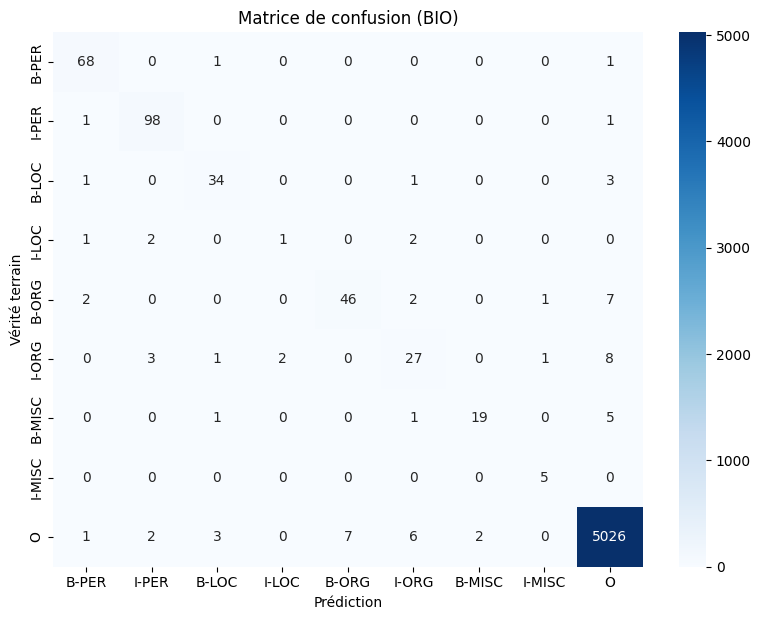

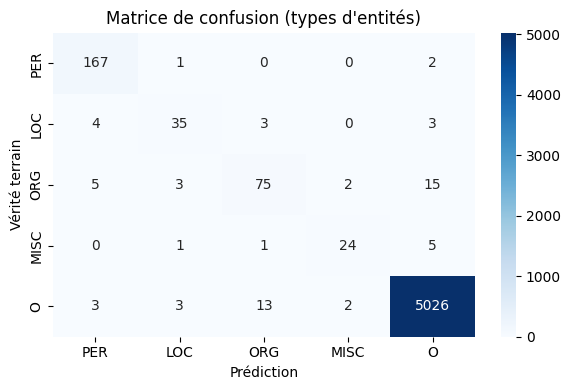

In [ ]:
def plot_cm(y_true_seqs, y_pred_seqs, labels, title):
    yt = [t for seq in y_true_seqs for t in seq]
    yp = [t for seq in y_pred_seqs for t in seq]
    cm = confusion_matrix(yt, yp, labels=labels)                                    # classes absentes du test
    rows = [i for i, l in enumerate(labels)]
    plt.figure(figsize=(max(6, 0.9 * len(labels)), max(4, 0.7 * len(rows))))
    sns.heatmap(cm[rows, :], annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=[labels[i] for i in rows])
    plt.xlabel("Prédiction")
    plt.ylabel("Vérité terrain")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# 1) Niveau tags BIO
# Desired order: PER, LOC, ORG, MISC, O
labels_bio_ordered = ['B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG', 'B-MISC', 'I-MISC', 'O']
# Filter and sort to ensure only existing tags are included and maintain order
labels_bio = [tag for tag in labels_bio_ordered if tag in all_tags]
plot_cm(y_test, y_test_pred_final, labels_bio,
             "Matrice de confusion (BIO)")

